git clone https://github.com/dogukannulu/docker-airflow.git

docker build --rm --build-arg AIRFLOW_DEPS="datadog,dask" --build-arg PYTHON_DEPS="flask_oauthlib>=0.9" -t puckel/docker-airflow .

docker-compose -f docker-compose-LocalExecutor.yml up -d

docker exec -it <airflow_container_name> /bin/bash
curl -O <https://bootstrap.pypa.io/get-pip.py>
sudo yum install -y python3 python3-devel
python3 get-pip.py --user
pip3 install <list all necessary libraries here>

In [ ]:
version: '3'

services:
  zoo1:
    image: confluentinc/cp-zookeeper:7.3.2
    ports:
      - "2181:2181"
    environment:
      ZOOKEEPER_CLIENT_PORT: 2181
      ZOOKEEPER_SERVER_ID: 1
      ZOOKEEPER_SERVERS: zoo1:2888:3888
    networks:
      - kafka-network
      - airflow-kafka

  kafka1:
    image: confluentinc/cp-kafka:7.3.2
    ports:
      - "9092:9092"
      - "29092:29092"
    environment:
      KAFKA_ADVERTISED_LISTENERS: INTERNAL://kafka1:19092,EXTERNAL://${DOCKER_HOST_IP:-127.0.0.1}:9092,DOCKER://host.docker.internal:29092
      KAFKA_LISTENER_SECURITY_PROTOCOL_MAP: INTERNAL:PLAINTEXT,EXTERNAL:PLAINTEXT,DOCKER:PLAINTEXT
      KAFKA_INTER_BROKER_LISTENER_NAME: INTERNAL
      KAFKA_ZOOKEEPER_CONNECT: "zoo1:2181"
      KAFKA_BROKER_ID: 1
      KAFKA_LOG4J_LOGGERS: "kafka.controller=INFO,kafka.producer.async.DefaultEventHandler=INFO,state.change.logger=INFO"
      KAFKA_AUTHORIZER_CLASS_NAME: kafka.security.authorizer.AclAuthorizer
      KAFKA_ALLOW_EVERYONE_IF_NO_ACL_FOUND: "true"
    networks:
      - kafka-network
      - airflow-kafka

  kafka2:
    image: confluentinc/cp-kafka:7.3.2
    ports:
      - "9093:9093"
      - "29093:29093"
    environment:
      KAFKA_ADVERTISED_LISTENERS: INTERNAL://kafka2:19093,EXTERNAL://${DOCKER_HOST_IP:-127.0.0.1}:9093,DOCKER://host.docker.internal:29093
      KAFKA_LISTENER_SECURITY_PROTOCOL_MAP: INTERNAL:PLAINTEXT,EXTERNAL:PLAINTEXT,DOCKER:PLAINTEXT
      KAFKA_INTER_BROKER_LISTENER_NAME: INTERNAL
      KAFKA_ZOOKEEPER_CONNECT: "zoo1:2181"
      KAFKA_BROKER_ID: 2
      KAFKA_LOG4J_LOGGERS: "kafka.controller=INFO,kafka.producer.async.DefaultEventHandler=INFO,state.change.logger=INFO"
      KAFKA_AUTHORIZER_CLASS_NAME: kafka.security.authorizer.AclAuthorizer
      KAFKA_ALLOW_EVERYONE_IF_NO_ACL_FOUND: "true"
    networks:
      - kafka-network
      - airflow-kafka

  kafka3:
    image: confluentinc/cp-kafka:7.3.2
    ports:
      - "9094:9094"
      - "29094:29094"
    environment:
      KAFKA_ADVERTISED_LISTENERS: INTERNAL://kafka3:19094,EXTERNAL://${DOCKER_HOST_IP:-127.0.0.1}:9094,DOCKER://host.docker.internal:29094
      KAFKA_LISTENER_SECURITY_PROTOCOL_MAP: INTERNAL:PLAINTEXT,EXTERNAL:PLAINTEXT,DOCKER:PLAINTEXT
      KAFKA_INTER_BROKER_LISTENER_NAME: INTERNAL
      KAFKA_ZOOKEEPER_CONNECT: "zoo1:2181"
      KAFKA_BROKER_ID: 3
      KAFKA_LOG4J_LOGGERS: "kafka.controller=INFO,kafka.producer.async.DefaultEventHandler=INFO,state.change.logger=INFO"
      KAFKA_AUTHORIZER_CLASS_NAME: kafka.security.authorizer.AclAuthorizer
      KAFKA_ALLOW_EVERYONE_IF_NO_ACL_FOUND: "true"
    networks:
      - kafka-network
      - airflow-kafka

  kafka-connect:
    image: confluentinc/cp-kafka-connect:7.3.2
    ports:
      - "8083:8083"
    environment:
      CONNECT_BOOTSTRAP_SERVERS: kafka1:19092,kafka2:19093,kafka3:19094
      CONNECT_REST_PORT: 8083
      CONNECT_GROUP_ID: compose-connect-group
      CONNECT_CONFIG_STORAGE_TOPIC: compose-connect-configs
      CONNECT_OFFSET_STORAGE_TOPIC: compose-connect-offsets
      CONNECT_STATUS_STORAGE_TOPIC: compose-connect-status
      CONNECT_KEY_CONVERTER: org.apache.kafka.connect.storage.StringConverter
      CONNECT_VALUE_CONVERTER: org.apache.kafka.connect.storage.StringConverter
      CONNECT_INTERNAL_KEY_CONVERTER: "org.apache.kafka.connect.json.JsonConverter"
      CONNECT_INTERNAL_VALUE_CONVERTER: "org.apache.kafka.connect.json.JsonConverter"
      CONNECT_REST_ADVERTISED_HOST_NAME: 'kafka-connect'
      CONNECT_LOG4J_ROOT_LOGLEVEL: 'INFO'
      CONNECT_LOG4J_LOGGERS: 'org.apache.kafka.connect.runtime.rest=WARN,org.reflections=ERROR'
      CONNECT_PLUGIN_PATH: '/usr/share/java,/usr/share/confluent-hub-components'
    networks:
      - kafka-network
      - airflow-kafka

  schema-registry:
    image: confluentinc/cp-schema-registry:7.3.2
    ports:
      - "8081:8081"
    environment:
      SCHEMA_REGISTRY_KAFKASTORE_BOOTSTRAP_SERVERS: kafka1:19092,kafka2:19093,kafka3:19094
      SCHEMA_REGISTRY_HOST_NAME: schema-registry
      SCHEMA_REGISTRY_LISTENERS: http://0.0.0.0:8081
    networks:
      - kafka-network
      - airflow-kafka

  kafka-ui:
    container_name: kafka-ui
    image: provectuslabs/kafka-ui:latest
    ports:
      - 8888:8080 # Changed to avoid port clash with akhq
    depends_on:
      - kafka1
      - kafka2
      - kafka3
      - schema-registry
      - kafka-connect
    environment:
      KAFKA_CLUSTERS_0_NAME: local
      KAFKA_CLUSTERS_0_BOOTSTRAPSERVERS: PLAINTEXT://kafka1:19092,PLAINTEXT_HOST://kafka1:19092
      KAFKA_CLUSTERS_0_SCHEMAREGISTRY: http://schema-registry:8081
      KAFKA_CLUSTERS_0_KAFKACONNECT_0_NAME: connect
      KAFKA_CLUSTERS_0_KAFKACONNECT_0_ADDRESS: http://kafka-connect:8083
      DYNAMIC_CONFIG_ENABLED: 'true'
    networks:
      - kafka-network
      - airflow-kafka

docker-compose up -d

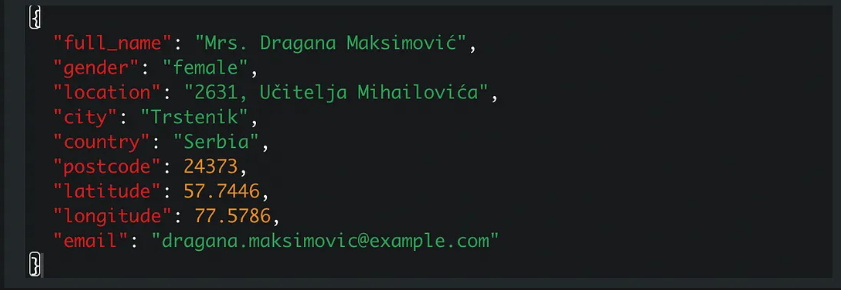

import requests
import json
import time
from kafka import KafkaProducer

In [ ]:
def create_response_dict(url: str="https://randomuser.me/api/?results=1") -> dict:
    """
    Creates the results JSON from the random user API call
    """
    response = requests.get(url)
    data = response.json()
    results = data["results"][0]

    return results


def create_final_json(results: dict) -> dict:
    """
    Creates the final JSON to be sent to Kafka topic only with necessary keys
    """
    kafka_data = {}

    kafka_data["full_name"] = f"{results['name']['title']}. {results['name']['first']} {results['name']['last']}"
    kafka_data["gender"] = results["gender"]
    kafka_data["location"] = f"{results['location']['street']['number']}, {results['location']['street']['name']}"
    kafka_data["city"] = results['location']['city']
    kafka_data["country"] = results['location']['country']
    kafka_data["postcode"] = int(results['location']['postcode'])
    kafka_data["latitude"] = float(results['location']['coordinates']['latitude'])
    kafka_data["longitude"] = float(results['location']['coordinates']['longitude'])
    kafka_data["email"] = results["email"]

    return kafka_data

In [ ]:
def create_kafka_producer():
    """
    Creates the Kafka producer object
    """

    return KafkaProducer(bootstrap_servers=['kafka1:19092', 'kafka2:19093', 'kafka3:19094'])


def start_streaming():
    """
    Writes the API data every 10 seconds to Kafka topic random_names
    """
    producer = create_kafka_producer()
    results = create_response_dict()
    kafka_data = create_final_json(results)    

    end_time = time.time() + 120 # the script will run for 2 minutes
    while True:
        if time.time() > end_time:
            break

        producer.send("random_names", json.dumps(kafka_data).encode('utf-8'))
        time.sleep(10)

In [ ]:
  cassandra:
    image: cassandra:latest
    container_name: cassandra
    hostname: cassandra
    ports:
      - 9042:9042
    environment:
      - MAX_HEAP_SIZE=512M
      - HEAP_NEWSIZE=100M
      - CASSANDRA_USERNAME=cassandra
      - CASSANDRA_PASSWORD=cassandra
    volumes:
      - ./:/home
      - cassandra-data:/var/lib/cassandra
    networks:
      - airflow-kafka
      - kafka-network

In [ ]:
docker exec -it cassandra /bin/bash

In [ ]:
cqlsh -u cassandra -p cassandra

In [ ]:
CREATE KEYSPACE spark_streaming WITH replication = {'class':'SimpleStrategy','replication_factor':1};

In [ ]:
CREATE TABLE spark_streaming.random_names(full_name text primary key, gender text, location text, city text, country text, postcode int, latitude float, longitude float, email text);
DESCRIBE spark_streaming.random_names;

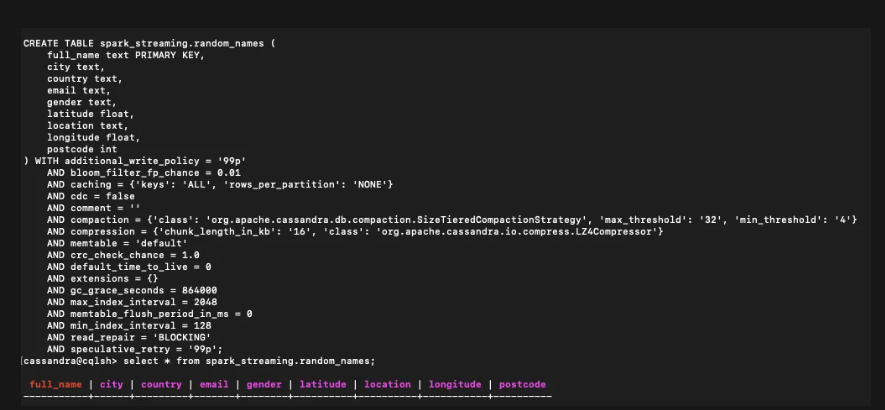

In [ ]:
from datetime import timedelta
from airflow import DAG
from airflow.operators.python_operator import PythonOperator
from datetime import datetime
from stream_to_kafka import start_streaming

start_date = datetime(2018, 12, 21, 12, 12)

default_args = {
    'owner': 'airflow',
    'start_date': start_date,
    'retries': 1,
    'retry_delay': timedelta(seconds=5)
}

with DAG('random_people_names', default_args=default_args, schedule_interval='0 1 * * *', catchup=False) as dag:


    data_stream_task = PythonOperator(
    task_id='kafka_data_stream',
    python_callable=start_streaming,
    dag=dag,
    )

    data_stream_task

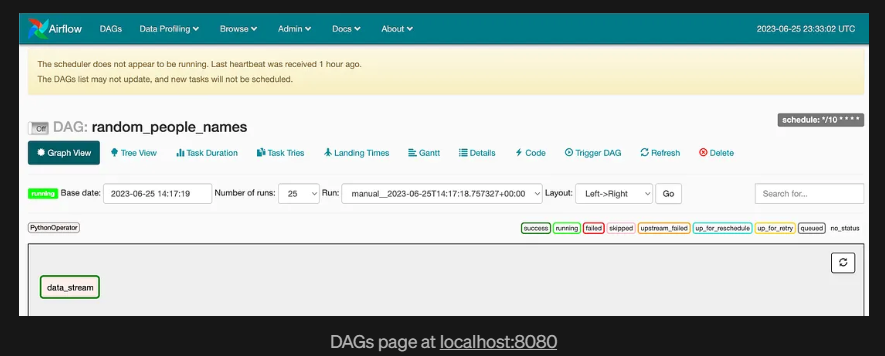

In [ ]:
docker exec -it <airflow_container_name> /bin/bash
curl -O <https://bootstrap.pypa.io/get-pip.py>
sudo yum install -y python3 python3-devel
python3 get-pip.py --user
pip3 install <list all necessary libraries here>

In [ ]:
import logging
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType,StructField,FloatType,IntegerType,StringType
from pyspark.sql.functions import from_json,col

logging.basicConfig(level=logging.INFO,
                    format='%(asctime)s:%(funcName)s:%(levelname)s:%(message)s')
logger = logging.getLogger("spark_structured_streaming")

In [ ]:
def create_spark_session():
    """
    Creates the Spark Session with suitable configs.
    """
    try:
        # Spark session is established with cassandra and kafka jars. Suitable versions can be found in Maven repository.
        spark = SparkSession \
                .builder \
                .appName("SparkStructuredStreaming") \
                .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.0.0,org.apache.spark:spark-sql-kafka-0-10_2.12:3.0.0") \
                .config("spark.cassandra.connection.host", "cassandra") \
                .config("spark.cassandra.connection.port","9042")\
                .config("spark.cassandra.auth.username", "cassandra") \
                .config("spark.cassandra.auth.password", "cassandra") \
                .getOrCreate()
        spark.sparkContext.setLogLevel("ERROR")
        logging.info('Spark session created successfully')
    except Exception:
        logging.error("Couldn't create the spark session")

    return spark

In [ ]:
def create_initial_dataframe(spark_session):
    """
    Reads the streaming data and creates the initial dataframe accordingly.
    """
    try:
        # Gets the streaming data from topic random_names
        df = spark_session \
              .readStream \
              .format("kafka") \
              .option("kafka.bootstrap.servers", "kafka1:19092,kafka2:19093,kafka3:19094") \
              .option("subscribe", "random_names") \
              .option("delimeter",",") \
              .option("startingOffsets", "earliest") \
              .load()
        logging.info("Initial dataframe created successfully")
    except Exception as e:
        logging.warning(f"Initial dataframe couldn't be created due to exception: {e}")

    return df


def create_final_dataframe(df, spark_session):
    """
    Modifies the initial dataframe, and creates the final dataframe.
    """
    schema = StructType([
                StructField("full_name",StringType(),False),
                StructField("gender",StringType(),False),
                StructField("location",StringType(),False),
                StructField("city",StringType(),False),
                StructField("country",StringType(),False),
                StructField("postcode",IntegerType(),False),
                StructField("latitude",FloatType(),False),
                StructField("longitude",FloatType(),False),
                StructField("email",StringType(),False)
            ])

    df = df.selectExpr("CAST(value AS STRING)").select(from_json(col("value"),schema).alias("data")).select("data.*")
    print(df)
    return df

In [ ]:
def start_streaming(df):
    """
    Starts the streaming to table spark_streaming.random_names in cassandra
    """
    logging.info("Streaming is being started...")
    my_query = (df.writeStream
                  .format("org.apache.spark.sql.cassandra")
                  .outputMode("append")
                  .options(table="random_names", keyspace="spark_streaming")\
                  .start())

    return my_query.awaitTermination()

In [ ]:
docker cp spark_streaming.py spark_master:/opt/bitnami/spark/

In [ ]:
docker exec -it spark_master /bin/bash

In [ ]:
cd jars
curl -O https://repo1.maven.org/maven2/com/datastax/spark/spark-cassandra-connector_2.12/3.3.0/spark-cassandra-connector_2.12-3.3.0.jar
curl -O https://repo1.maven.org/maven2/org/apache/spark/spark-sql-kafka-0-10_2.13/3.3.0/spark-sql-kafka-0-10_2.13-3.3.0.jar

In [ ]:
cd ..
spark-submit --master local[2] --jars /opt/bitnami/spark/jars/spark-sql-kafka-0-10_2.13-3.3.0.jar,/opt/bitnami/spark/jars/spark-cassandra-connector_2.12-3.3.0.jar spark_streaming.py

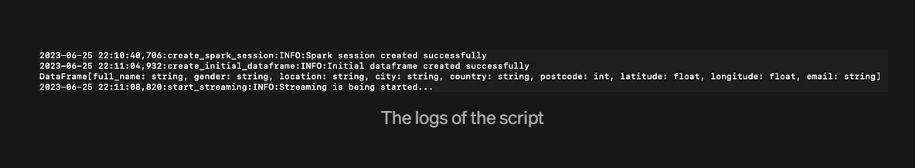